# Normal vectors of a polyline

## Imports

In [1]:
import cartopy.crs as ccrs
import earthkit.plots as ekp
import numpy as np

from earthkit.geo.distance import haversine_distance
from earthkit.geo.polyline import polyline_normals, sample_polyline

## The simplest case

A line along the equator heading east. Its normal points north, so ``east`` is 0 and ``north`` is 1 at every vertex (the values are rounded to hide floating-point noise).

In [2]:
lats, lons = sample_polyline([0, 0], [0, 40], n=5)
east, north = polyline_normals(lats, lons)

print("east: ", np.round(east, 6) + 0.0)
print("north:", np.round(north, 6) + 0.0)

east:  [0. 0. 0. 0. 0.]
north: [1. 1. 1. 1. 1.]


## The normal points to the left of the direction of travel

The direction of travel goes from the first vertex to the last one. If the unit tangent is ``(te, tn)`` the normal is ``(-tn, te)``: the tangent turned by 90° to the left.

Below, the same route is sampled from London to New York and back. The arrows are the normals drawn at the sampled points. They flip when the direction of travel is reversed. The Mercator projection keeps angles, so the arrows look perpendicular to the line. The green dot is the start.

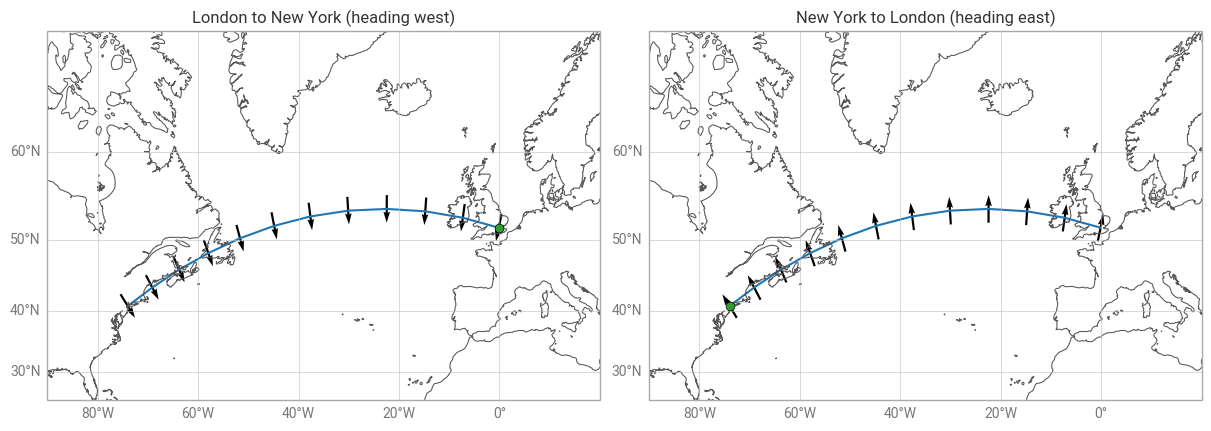

In [3]:
def draw(m, lats, lons, east, north, color="tab:blue"):
    """Draw a line and its normals on a map."""
    m.line(lons, lats, color=color, linewidth=1.5)
    m.quiver(x=lons, y=lats, u=east, v=north, resample=False, scale=20, width=0.004, color="k")
    m.coastlines()
    m.gridlines()


london = (51.51, -0.13)
new_york = (40.71, -74.01)
domain = [-90, 20, 25, 70]

fig = ekp.Figure(rows=1, columns=2, figsize=(12, 5))
titles = ["London to New York (heading west)", "New York to London (heading east)"]
for (start, end), title in zip([(london, new_york), (new_york, london)], titles):
    lats, lons = sample_polyline([start[0], end[0]], [start[1], end[1]], n=12)
    east, north = polyline_normals(lats, lons)
    m = fig.add_map(domain=domain, crs=ccrs.Mercator())
    draw(m, lats, lons, east, north)
    m.scatter([start[1]], [start[0]], color="tab:green", s=40, zorder=5)
    m.title(title)
fig.show()

## Interior vertices

A polyline with several waypoints has corners. At the first and the last vertex the normal belongs to the only segment there. At an interior vertex the tangent is the bisector of the direction of travel arriving at the vertex and the one leaving it, so the normal is the normalised sum of the normals of the two segments.

The orange arrows below are the normals of each segment on its own (computed from its two end vertices) and the black arrows are the result of ``polyline_normals`` for the whole line. At the ends they are the same; at the corners the black arrow lies between the two orange ones. The line goes from west to east.

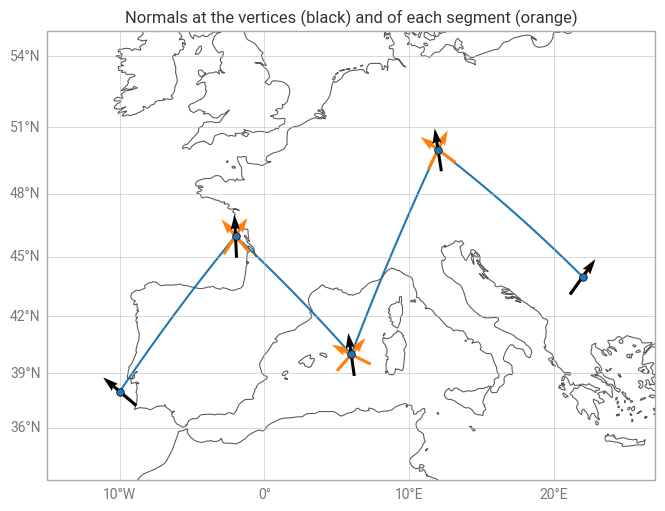

In [4]:
wp_lats = np.array([38.0, 46.0, 40.0, 50.0, 44.0])
wp_lons = np.array([-10.0, -2.0, 6.0, 12.0, 22.0])

lats, lons = sample_polyline(wp_lats, wp_lons, n=60)
east, north = polyline_normals(wp_lats, wp_lons)

# normals of each segment on its own: element 0 is at its start, element 1 at its end
segments = [polyline_normals(wp_lats[i : i + 2], wp_lons[i : i + 2]) for i in range(len(wp_lats) - 1)]

fig = ekp.Figure(rows=1, columns=1, figsize=(8, 5))
m = fig.add_map(domain=[-15, 27, 33, 55], crs=ccrs.Mercator())
m.line(lons, lats, color="tab:blue", linewidth=1.5)
for i, (e_seg, n_seg) in enumerate(segments):
    x, y = wp_lons[i : i + 2], wp_lats[i : i + 2]
    m.quiver(x=x, y=y, u=e_seg, v=n_seg, resample=False, scale=14, width=0.005, color="tab:orange", zorder=4)
m.quiver(x=wp_lons, y=wp_lats, u=east, v=north, resample=False, scale=14, width=0.005, color="k", zorder=5)
m.scatter(wp_lons, wp_lats, color="tab:blue", s=30, zorder=6)
m.coastlines()
m.gridlines()
m.title("Normals at the vertices (black) and of each segment (orange)")
fig.show()

The normalised sum of the two segment normals at an interior vertex is the normal of the bisector. Check at vertex 2:

In [5]:
n_in = np.array([segments[1][0][1], segments[1][1][1]])  # arriving at vertex 2: end of segment 1
n_out = np.array([segments[2][0][0], segments[2][1][0]])  # leaving vertex 2: start of segment 2
total = n_in + n_out
bisector = total / np.hypot(*total)

print("bisector of the segment normals:", np.round(bisector, 6))
print("polyline_normals at vertex 2:   ", np.round([east[2], north[2]], 6))

bisector of the segment normals: [-0.179661  0.983729]
polyline_normals at vertex 2:    [-0.179661  0.983729]


## Use the same method in both functions

Both functions have a ``method`` argument (``"great_circle"``, ``"rhumb"`` or ``"linear"``) and the normals follow the path that ``sample_polyline`` draws, so pass the same ``method`` to both. Here the London to New York route is sampled twice. A great circle keeps changing its heading, so its normals turn along the way. A rhumb line has a constant bearing, so all its normals are parallel.

great_circle: east -0.314 to 0.627, north -1.000 to -0.779
       rhumb: east 0.207 to 0.207, north -0.978 to -0.978


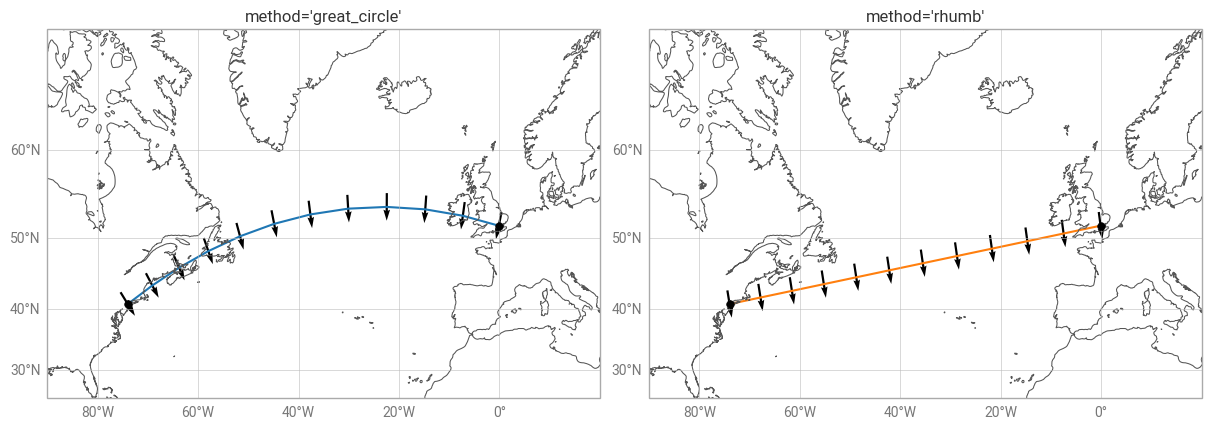

In [6]:
fig = ekp.Figure(rows=1, columns=2, figsize=(12, 5))
colours = {"great_circle": "tab:blue", "rhumb": "tab:orange"}
for method, colour in colours.items():
    lats, lons = sample_polyline([london[0], new_york[0]], [london[1], new_york[1]], n=12, method=method)
    east, north = polyline_normals(lats, lons, method=method)
    m = fig.add_map(domain=domain, crs=ccrs.Mercator())
    draw(m, lats, lons, east, north, color=colour)
    m.scatter(lons[[0, -1]], lats[[0, -1]], color="k", s=30, zorder=5)
    m.title(f"method={method!r}")
    print(f"{method:>12}: east {east.min():.3f} to {east.max():.3f}, north {north.min():.3f} to {north.max():.3f}")
fig.show()

## Application: wind across and along a line

A cross-section needs the wind component across the line (perpendicular to it) and along it. With the normal ``(east, north)`` and a wind ``(u, v)``:

- across the line (positive to the left of the direction of travel): ``u * east + v * north``
- along the line (positive in the direction of travel): the tangent is ``(te, tn) = (north, -east)``, so ``u * north - v * east``

First a check on the east-heading equator line, where the across component must be ``v`` and the along component ``u``.

In [7]:
def wind_across_along(u, v, east, north):
    """Split the wind (u, v) in the components across and along a line with normals (east, north)."""
    across = u * east + v * north
    along = u * north - v * east
    return across, along


u, v = 10.0, 5.0  # a uniform wind in m/s

lats, lons = sample_polyline([0, 0], [0, 40], n=5)
east, north = polyline_normals(lats, lons)
across, along = wind_across_along(u, v, east, north)

print("across:", np.round(across, 6) + 0.0, "(expected v =", v, ")")
print("along: ", np.round(along, 6) + 0.0, "(expected u =", u, ")")

across: [5. 5. 5. 5. 5.] (expected v = 5.0 )
along:  [10. 10. 10. 10. 10.] (expected u = 10.0 )


Now the London to New York line. The distance along the line is the sum of the great circle distances between consecutive points. The two components together keep the wind speed, which is a second check.

line length (km): 5571
speed is kept: True


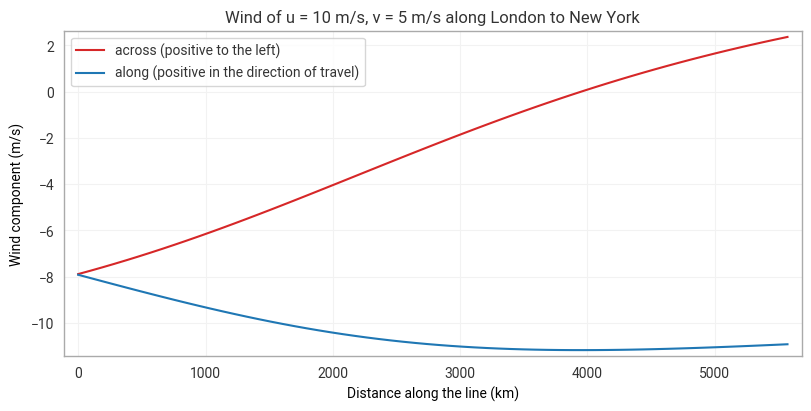

In [8]:
lats, lons = sample_polyline([london[0], new_york[0]], [london[1], new_york[1]], n=60)
east, north = polyline_normals(lats, lons)
across, along = wind_across_along(u, v, east, north)

steps = [haversine_distance((lats[i], lons[i]), (lats[i + 1], lons[i + 1])) for i in range(len(lats) - 1)]
distance = np.concatenate([[0.0], np.cumsum(steps)]) / 1000  # km

print("line length (km):", round(distance[-1]))
print("speed is kept:", np.allclose(np.hypot(across, along), np.hypot(u, v)))

chart = ekp.Subplot(figsize=(8, 4))
chart.line(x=distance, y=across, label="across (positive to the left)", color="tab:red")
chart.line(x=distance, y=along, label="along (positive in the direction of travel)", color="tab:blue")
chart.xlabel("Distance along the line (km)")
chart.ylabel("Wind component (m/s)")
chart.legend()
chart.title("Wind of u = 10 m/s, v = 5 m/s along London to New York")
chart.show()

The line starts heading west-north-west, so the eastward wind is mostly a headwind (negative along component) and it blows to the right of the line (negative across component). The line turns towards the south-west and after about 4000 km the across component becomes positive.

## See also

- [Sampling points along a polyline](sample_polyline.ipynb): how to create the points of a polyline.
- [API reference](../../api-reference.rst): ``earthkit.geo.polyline.polyline_normals`` and ``earthkit.geo.polyline.sample_polyline``.